# Week 11-12 · Part 3: PCA vs t-SNE + Mini Project

Compare both methods side by side and use them in a small end-to-end analysis.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, time
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.datasets import make_swiss_roll
sns.set_theme(style="whitegrid")

## 1. Digits: PCA vs t-SNE

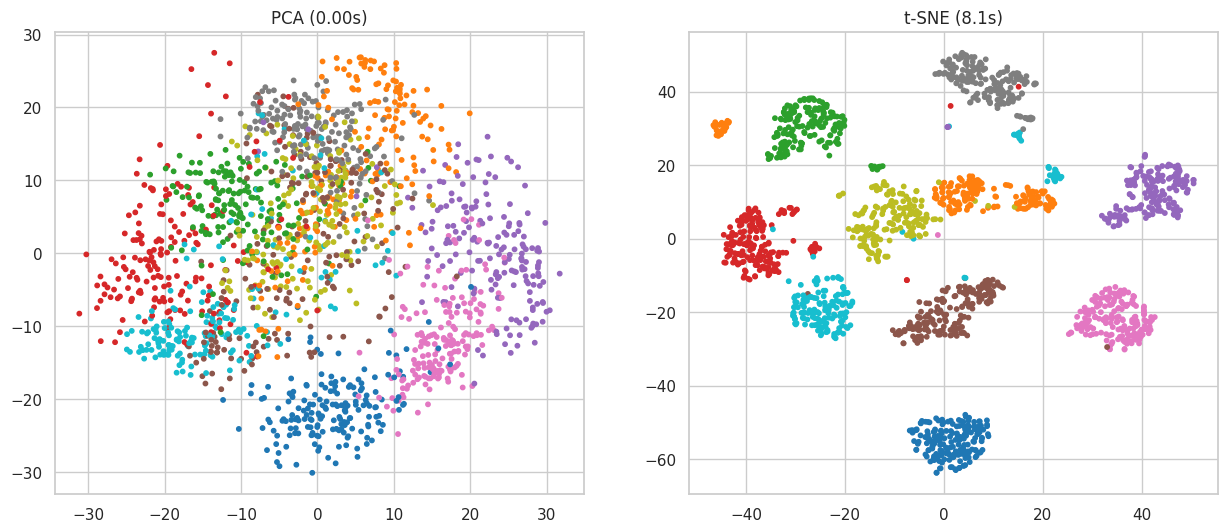

In [2]:
d = pd.read_csv("../data/digits.csv"); X = d.drop(columns="target").values; y = d["target"].values
t=time.time(); Zp = PCA(2).fit_transform(X); tp=time.time()-t
t=time.time(); Zt = TSNE(init="pca", learning_rate="auto", random_state=0).fit_transform(X); tt=time.time()-t

fig, ax = plt.subplots(1,2, figsize=(15,6))
ax[0].scatter(Zp[:,0], Zp[:,1], c=y, cmap="tab10", s=10); ax[0].set_title(f"PCA ({tp:.2f}s)")
ax[1].scatter(Zt[:,0], Zt[:,1], c=y, cmap="tab10", s=10); ax[1].set_title(f"t-SNE ({tt:.1f}s)")
plt.show()

## 2. Quantify: how well does each 2D embedding separate the classes? (5-fold kNN accuracy)

In [3]:
knn = KNeighborsClassifier(n_neighbors=10)
print("PCA   2D kNN accuracy:", cross_val_score(knn, Zp, y, cv=5).mean().round(3))
print("t-SNE 2D kNN accuracy:", cross_val_score(knn, Zt, y, cv=5).mean().round(3))
print("Original 64D accuracy:", cross_val_score(knn, X, y, cv=5).mean().round(3))
print("\nNote: t-SNE was fit on ALL data, so this is for visual-quality comparison only, not a fair ML evaluation.")

PCA   2D kNN accuracy: 0.613
t-SNE 2D kNN accuracy: 0.974
Original 64D accuracy: 0.955

Note: t-SNE was fit on ALL data, so this is for visual-quality comparison only, not a fair ML evaluation.


## 3. Non-linear structure: Swiss roll
PCA only finds linear directions, so it cannot 'unroll' the roll.

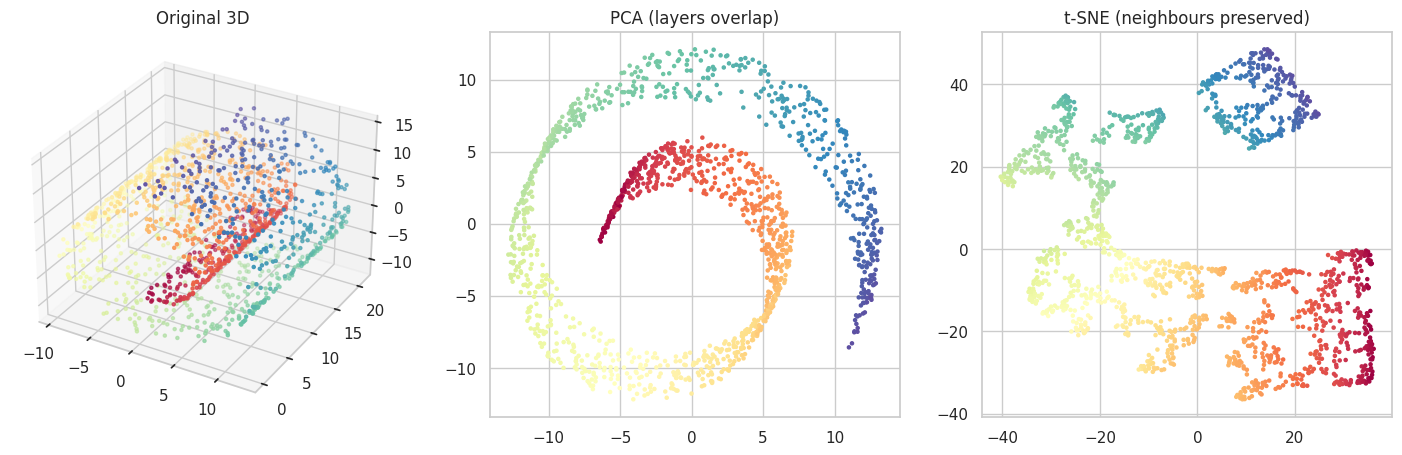

In [4]:
Xs, color = make_swiss_roll(n_samples=1500, noise=0.05, random_state=0)
Zp = PCA(2).fit_transform(Xs)
Zt = TSNE(perplexity=30, init="pca", learning_rate="auto", random_state=0).fit_transform(Xs)

fig = plt.figure(figsize=(18,5))
ax = fig.add_subplot(131, projection="3d"); ax.scatter(*Xs.T, c=color, cmap="Spectral", s=5); ax.set_title("Original 3D")
ax = fig.add_subplot(132); ax.scatter(Zp[:,0], Zp[:,1], c=color, cmap="Spectral", s=5); ax.set_title("PCA (layers overlap)")
ax = fig.add_subplot(133); ax.scatter(Zt[:,0], Zt[:,1], c=color, cmap="Spectral", s=5); ax.set_title("t-SNE (neighbours preserved)")
plt.show()

## 4. Comparison table
| | **PCA** | **t-SNE** |
|---|---|---|
| Linear / non-linear | Linear | Non-linear |
| Preserves | Global variance | Local neighbours |
| Deterministic | Yes | No |
| Speed | Very fast | Slow |
| New data (`transform`) | Yes | No |
| Axes interpretable | Somewhat (loadings) | No |
| Cluster distances meaningful | Yes | No |
| Hyperparameters | n_components | perplexity, lr, iterations |
| Best for | Preprocessing, compression, noise reduction | Visual exploration of clusters |

**Rule of thumb:** use PCA to *reduce/clean*, use t-SNE to *look*. Often: PCA -> t-SNE.

## 5. Mini project: Explore the Wine dataset
Fill in your own analysis below:
1. Standardise features.
2. How many PCs for 90% variance?
3. Plot PCA 2D and t-SNE 2D.
4. Which technique separates the 3 wine types better? Explain in 3-4 sentences.

In [5]:
# Your code here
wine = pd.read_csv("../data/wine.csv")


## Learning checklist
- [ ] I can explain PCA as "rotate axes to maximise variance and keep the top k".
- [ ] I can read a scree plot and choose k.
- [ ] I know why scaling matters before PCA.
- [ ] I can explain t-SNE as "keep neighbours close in 2D".
- [ ] I know what perplexity does and how not to misread a t-SNE plot.
- [ ] I can choose between PCA and t-SNE for a given task.